In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C3"
DTYPE="G_H"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C3_10,27,"[DATA/TRAINING/C3/C3_10/IMG_6627.HEIC, DATA/TR..."
1,C3_11,27,"[DATA/TRAINING/C3/C3_11/IMG_6732.HEIC, DATA/TR..."
2,C3_12,27,"[DATA/TRAINING/C3/C3_12/IMG_6854.HEIC, DATA/TR..."
3,C3_13,30,"[DATA/TRAINING/C3/C3_13/IMG_7002.HEIC, DATA/TR..."
4,C3_14,27,"[DATA/TRAINING/C3/C3_14/IMG_7249.HEIC, DATA/TR..."
5,C3_15,26,"[DATA/TRAINING/C3/C3_15/IMG_7385.HEIC, DATA/TR..."
6,C3_16,26,"[DATA/TRAINING/C3/C3_16/IMG_7516.HEIC, DATA/TR..."


In [8]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [9]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [10]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

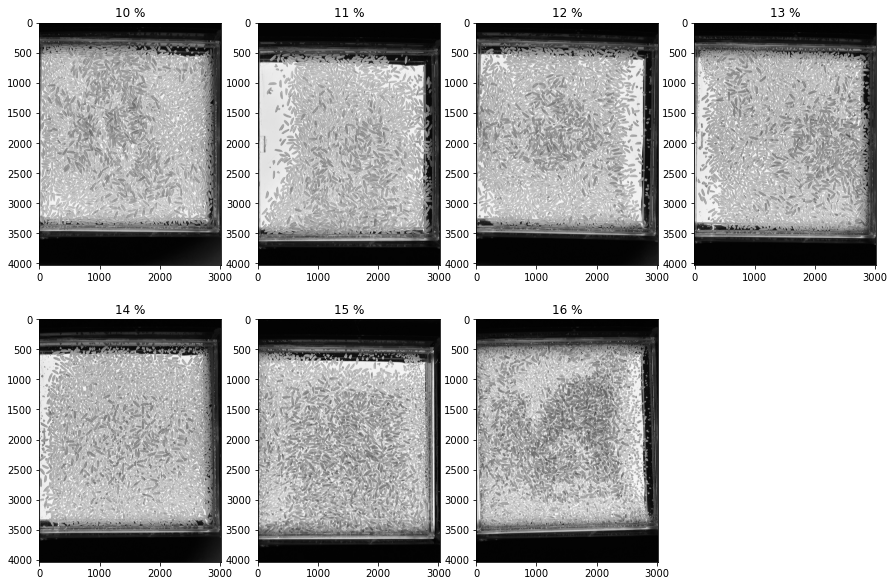

In [11]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image)
ax7.imshow(image); ax7.set_title("16 %")

In [12]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [159]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [160]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.552100,0.094853,0.114307,0.111585,0.058871,0.043141,0.051762,0.048143,0.049445,0.040425,...,0.340556,0.096426,0.004117,25,44,1008,756,3,IMG_6627.HEIC,10
1,0.564521,0.131987,0.133085,0.084865,0.069667,0.071766,0.074958,0.053001,0.044677,0.034909,...,0.166005,0.130094,0.007911,25,44,1008,756,3,IMG_6628.HEIC,10
2,0.588091,0.103829,0.127782,0.104932,0.072399,0.051874,0.054694,0.035479,0.040549,0.032163,...,0.127958,0.102695,0.017993,25,44,1008,756,3,IMG_6629.HEIC,10
3,0.594113,0.108254,0.147408,0.097243,0.066088,0.067761,0.072169,0.047765,0.043473,0.036863,...,0.115546,0.106948,0.021102,25,44,1008,756,3,IMG_6630.HEIC,10
4,0.577848,0.103065,0.118957,0.102144,0.073298,0.049002,0.052469,0.045398,0.037324,0.035980,...,0.100432,0.126583,0.017019,25,44,1008,756,3,IMG_6631.HEIC,10
5,0.583499,0.098001,0.122527,0.084182,0.057629,0.053991,0.061488,0.053757,0.044131,0.039369,...,0.102214,0.096416,0.015588,25,44,1008,756,3,IMG_6632.HEIC,10
6,0.618845,0.137147,0.124664,0.105099,0.061777,0.052678,0.047677,0.033427,0.028376,0.024509,...,0.116135,0.105582,0.015473,25,44,1008,756,3,IMG_6633.HEIC,10
7,0.575619,0.093467,0.106828,0.108038,0.062366,0.056645,0.060130,0.050620,0.046021,0.039318,...,0.086080,0.108792,0.010973,25,44,1008,756,3,IMG_6634.HEIC,10
8,0.587279,0.104880,0.144974,0.086581,0.056247,0.056279,0.075326,0.072407,0.058502,0.044028,...,0.093862,0.098659,0.018523,25,44,1008,756,3,IMG_6635.HEIC,10
9,0.581268,0.119276,0.134414,0.070456,0.048992,0.043733,0.062980,0.069747,0.056021,0.046590,...,0.118343,0.132529,0.019873,25,44,1008,756,3,IMG_6636.HEIC,10


# Classification

In [161]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-7]
#X

In [162]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [163]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [164]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

### Random Forest Classifier

In [165]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.842105,0.869048,0.857143,0.863054,G_H,C3,RF_C,25,44,1008,756,3
1,2,0.684211,0.738095,0.690476,0.713492,G_H,C3,RF_C,25,44,1008,756,3
2,3,0.947368,0.964286,0.952381,0.958296,G_H,C3,RF_C,25,44,1008,756,3
3,4,0.631579,0.761905,0.666667,0.711111,G_H,C3,RF_C,25,44,1008,756,3
4,5,0.684211,0.750000,0.690476,0.719008,G_H,C3,RF_C,25,44,1008,756,3
5,6,0.842105,0.880952,0.857143,0.868885,G_H,C3,RF_C,25,44,1008,756,3
6,7,0.736842,0.785714,0.761905,0.773626,G_H,C3,RF_C,25,44,1008,756,3
7,8,0.684211,0.690476,0.714286,0.702179,G_H,C3,RF_C,25,44,1008,756,3
8,9,0.736842,0.821429,0.761905,0.790548,G_H,C3,RF_C,25,44,1008,756,3
9,10,0.789474,0.845238,0.785714,0.814390,G_H,C3,RF_C,25,44,1008,756,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C3,RF_C,0.757895,0.77381,0.791459,0.810714


### MLP Classifier

In [169]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [170]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [171]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.947368,0.952381,0.952381,0.952381,G_H,C3,MLP_C,25,44,1008,756,3
1,2,0.842105,0.869048,0.833333,0.850816,G_H,C3,MLP_C,25,44,1008,756,3
2,3,0.736842,0.773810,0.738095,0.755531,G_H,C3,MLP_C,25,44,1008,756,3
3,4,0.894737,0.942857,0.904762,0.923417,G_H,C3,MLP_C,25,44,1008,756,3
4,5,0.894737,0.928571,0.904762,0.916512,G_H,C3,MLP_C,25,44,1008,756,3
5,6,0.894737,0.916667,0.880952,0.898455,G_H,C3,MLP_C,25,44,1008,756,3
6,7,0.736842,0.785714,0.738095,0.761161,G_H,C3,MLP_C,25,44,1008,756,3
7,8,0.842105,0.892857,0.857143,0.874636,G_H,C3,MLP_C,25,44,1008,756,3
8,9,0.631579,0.654762,0.619048,0.636404,G_H,C3,MLP_C,25,44,1008,756,3
9,10,0.894737,0.904762,0.904762,0.904762,G_H,C3,MLP_C,25,44,1008,756,3


In [172]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C3,MLP_C,0.831579,0.833333,0.847407,0.862143


### XGBoost Classifier

In [173]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [174]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["bins"]=bins; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,bins,height,width,channels
0,1,0.842105,0.907143,0.833333,0.868673,G_H,C3,XGB_C,25,44,1008,756,3
1,2,0.842105,0.869048,0.857143,0.863054,G_H,C3,XGB_C,25,44,1008,756,3
2,3,0.684211,0.761905,0.690476,0.724434,G_H,C3,XGB_C,25,44,1008,756,3
3,4,0.473684,0.440476,0.476190,0.457638,G_H,C3,XGB_C,25,44,1008,756,3
4,5,0.736842,0.750000,0.714286,0.731707,G_H,C3,XGB_C,25,44,1008,756,3
5,6,0.631579,0.654762,0.619048,0.636404,G_H,C3,XGB_C,25,44,1008,756,3
6,7,0.736842,0.809524,0.738095,0.772161,G_H,C3,XGB_C,25,44,1008,756,3
7,8,0.789474,0.859524,0.785714,0.820963,G_H,C3,XGB_C,25,44,1008,756,3
8,9,0.789474,0.797619,0.809524,0.803527,G_H,C3,XGB_C,25,44,1008,756,3
9,10,0.789474,0.797619,0.809524,0.803527,G_H,C3,XGB_C,25,44,1008,756,3


In [175]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,G_H,C3,XGB_C,0.731579,0.733333,0.748209,0.764762


# External validation


In [176]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C3_10,5,"[DATA/TEST/C3/C3_10/IMG_6622.HEIC, DATA/TEST/C..."
1,C3_11,5,"[DATA/TEST/C3/C3_11/IMG_6717.HEIC, DATA/TEST/C..."
2,C3_12,5,"[DATA/TEST/C3/C3_12/IMG_6845.HEIC, DATA/TEST/C..."
3,C3_13,5,"[DATA/TEST/C3/C3_13/IMG_6987.HEIC, DATA/TEST/C..."
4,C3_14,5,"[DATA/TEST/C3/C3_14/IMG_7239.HEIC, DATA/TEST/C..."
5,C3_15,5,"[DATA/TEST/C3/C3_15/IMG_7376.HEIC, DATA/TEST/C..."
6,C3_16,5,"[DATA/TEST/C3/C3_16/IMG_7506.HEIC, DATA/TEST/C..."


In [177]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [178]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        #imCrop=centerCrop(image, width, height)
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        #Compute 1D gray histogram
        [grayHist, grayNormHist]=fd_gray(gray, bins)
        arr_img_hist.append(grayNormHist)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["bins"] = bins
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [179]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(bins)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,41,42,43,scale,bins,height,width,channels,IMAGENAME,HUMIDITY
0,0.622223,0.148881,0.120583,0.084547,0.063149,0.053727,0.054132,0.039913,0.029544,0.025622,...,0.236753,0.134120,0.029459,25,44,1008,756,3,IMG_6622.HEIC,10
1,0.646659,0.147969,0.110049,0.082551,0.059577,0.051530,0.054053,0.037489,0.028755,0.021439,...,0.132794,0.141807,0.026984,25,44,1008,756,3,IMG_6623.HEIC,10
2,0.602588,0.144142,0.140724,0.090954,0.070514,0.064532,0.066217,0.041435,0.030541,0.025312,...,0.201287,0.122385,0.033695,25,44,1008,756,3,IMG_6624.HEIC,10
3,0.596366,0.135168,0.128167,0.086316,0.067667,0.065083,0.061657,0.038722,0.031801,0.028134,...,0.225804,0.135480,0.029589,25,44,1008,756,3,IMG_6625.HEIC,10
4,0.544360,0.109194,0.117274,0.094113,0.064082,0.050958,0.053165,0.046159,0.041747,0.038147,...,0.148809,0.173131,0.033813,25,44,1008,756,3,IMG_6626.HEIC,10
0,0.666658,0.070009,0.091374,0.114442,0.064457,0.032435,0.038740,0.041413,0.038575,0.031522,...,0.074844,0.121993,0.038922,25,44,1008,756,3,IMG_6717.HEIC,11
1,0.677714,0.075190,0.104037,0.089113,0.073314,0.052815,0.058004,0.056728,0.046265,0.037077,...,0.113291,0.122452,0.036481,25,44,1008,756,3,IMG_6721.HEIC,11
2,0.642949,0.067914,0.085662,0.080293,0.051629,0.045003,0.048096,0.056492,0.048237,0.039050,...,0.127696,0.142927,0.038827,25,44,1008,756,3,IMG_6724.HEIC,11
3,0.662603,0.075767,0.108786,0.098908,0.069664,0.045582,0.048728,0.050626,0.041209,0.032963,...,0.121303,0.109803,0.036289,25,44,1008,756,3,IMG_6728.HEIC,11
4,0.660706,0.073159,0.077646,0.098358,0.066623,0.045056,0.046907,0.042762,0.039975,0.036222,...,0.119360,0.117964,0.034281,25,44,1008,756,3,IMG_6731.HEIC,11


In [180]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [181]:
X_test = dtFeaturesTest.values[:, :-7]
#X_test

In [182]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [183]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [184]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.40      0.40      0.40         5
     Class 1       1.00      0.60      0.75         5
     Class 2       0.50      1.00      0.67         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.67      0.40      0.50         5
     Class 5       0.67      0.40      0.50         5
     Class 6       0.71      1.00      0.83         5

    accuracy                           0.54        35
   macro avg       0.56      0.54      0.52        35
weighted avg       0.56      0.54      0.52        35



## MLP

In [185]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [186]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.20      0.33         5
     Class 1       0.00      0.00      0.00         5
     Class 2       0.19      1.00      0.31         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.00      0.00      0.00         5
     Class 5       1.00      0.40      0.57         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.34        35
   macro avg       0.46      0.34      0.30        35
weighted avg       0.46      0.34      0.30        35



## XGBC

In [187]:
y_pred = modelXGBC.predict(X_test_scale) 

In [188]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.00      0.00      0.00         5
     Class 2       0.26      1.00      0.42         5
     Class 3       0.25      0.20      0.22         5
     Class 4       0.25      0.20      0.22         5
     Class 5       1.00      0.40      0.57         5
     Class 6       0.00      0.00      0.00         5

    accuracy                           0.26        35
   macro avg       0.25      0.26      0.20        35
weighted avg       0.25      0.26      0.20        35

